# EV Battery Failure Prediction — Exploratory Data Analysis and Modeling

This notebook explores an EV battery failure dataset, prepares numerical and categorical
features, compares classification models, and evaluates the selected model on a held-out
test set.

## Notebook workflow

1. Load and inspect the dataset.
2. Examine missing values, target relationships, and potentially engineered features.
3. Split the data and build preprocessing pipelines.
4. Visualize important patterns in the dataset.
5. Train Logistic Regression, Random Forest, and Extra Trees classifiers.
6. Select a decision threshold using validation data and report final test metrics.

**Target:** `battery_failure` (assumed to be encoded as `0 = No Failure` and `1 = Failure`
where those labels are used in plots and reports).

> Run the notebook from top to bottom. The CSV file should be named with the
> `ev_battery_failure` prefix and be located in the notebook's working directory or
> one of its subdirectories. The notebook does not include the dataset itself.

## Part 1 — Exploratory data analysis and preprocessing

This section loads the data and investigates its structure and quality before modeling.

### 1. Import libraries

Import the data-handling, visualization, and scikit-learn preprocessing utilities used throughout the EDA and preprocessing workflow.

In [1]:
# EV Battery Failure Dataset - Corrected EDA and Preprocessing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------

### 2. Load the dataset

Search recursively from the current working directory for a matching CSV file, load the first match, and preview representative rows.

In [2]:
# 1. Load dataset
# --------------------------------------------------

# Search the current Jupyter folder and its subfolders
files = list(Path.cwd().rglob("ev_battery_failure*.csv"))

if not files:
    raise FileNotFoundError(
        "CSV not found. Put ev_battery_failure_dataset.csv "
        "inside the Jupyter working folder or update the file path."
    )

file_path = files[0]
print("Dataset path:", file_path)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
display(df.head())
display(df.tail())
display(df.sample(min(5, len(df)), random_state=42))

# --------------------------------------------------

Dataset path: D:\machine_learning_projects\New folder\ev_battery_failure_dataset.csv
Dataset loaded successfully!


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
199995,EV299995,BYD,Song Plus,Hatchback,2016.0,CATL,LFP,45.99,FWD,182311.0,...,3.0,1.0,1.0,62.3,NaN,78.6,0.0,51.5,2691.0,0
199996,EV299996,Lucid,Air,Crossover,2015.0,LG Energy Solution,NMC,67.65,AWD,275317.0,...,2.0,5.0,2.0,33.1,89.5,59.3,73.7,57.0,420.0,0
199997,EV299997,BYD,Song Plus,SUV,NaN,BYD Battery,LFP,98.08,FWD,158747.0,...,2.0,2.0,0.0,79.0,13.1,64.7,32.8,7.6,3148.0,0
199998,EV299998,Tesla,Model Y,Hatchback,2016.0,SK On,NMC,51.49,FWD,95122.0,...,2.0,2.0,0.0,24.3,59.5,50.6,69.4,12.7,797.0,0
199999,EV299999,Tesla,Model 3,SUV,2024.0,CATL,NCA,88.39,RWD,54982.0,...,0.0,1.0,1.0,47.7,16.6,49.6,32.0,70.8,925.0,0


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
119737,EV219737,Tesla,Model 3,SUV,2015.0,Samsung SDI,NMC,95.33,FWD,231842.0,...,3.0,2.0,0.0,94.4,88.9,52.4,52.0,78.1,690.0,1
72272,EV172272,Nissan,Leaf,Crossover,2016.0,Panasonic,NMC,83.07,FWD,233321.0,...,4.0,4.0,0.0,23.8,70.5,58.1,85.1,34.9,703.0,0
158154,EV258154,Ford,Mustang Mach-E,Sedan,2018.0,CATL,LFP,83.88,FWD,219348.0,...,2.0,0.0,0.0,12.1,11.9,NaN,100.0,2.8,3634.0,0
65426,EV165426,Tesla,Model Y,Crossover,2017.0,LG Energy Solution,NaN,71.12,AWD,50838.0,...,1.0,NaN,1.0,NaN,39.5,53.6,56.1,20.5,NaN,0
30074,EV130074,Ford,Mustang Mach-E,SUV,2016.0,CATL,LFP,77.77,RWD,151584.0,...,4.0,2.0,3.0,3.5,30.9,83.8,57.7,20.5,3477.0,0


### 3. Inspect dataset structure

Review column names, dimensions, descriptive statistics, data types, and missing-value counts. This establishes the dataset's basic quality and schema.

In [3]:
# 2. Basic dataset inspection
# --------------------------------------------------

print("Columns:")
print(df.columns.tolist())

print("\nShape:", df.shape)

display(df.describe(include="all").T)

df.info()

print("\nMissing values:")
display(df.isnull().sum())

# Missing count and percentage
mis = pd.DataFrame({
    "count": df.isnull().sum(),
    "percent": df.isnull().mean() * 100
})
display(mis.sort_values("count", ascending=False))

# --------------------------------------------------

Columns:
['vehicle_id', 'vehicle_brand', 'vehicle_model', 'vehicle_type', 'manufacturing_year', 'battery_manufacturer', 'battery_chemistry', 'battery_capacity_kwh', 'drive_type', 'odometer_km', 'vehicle_age_years', 'fleet_or_private', 'battery_serial', 'cycle_count', 'battery_health_percent', 'state_of_charge', 'depth_of_discharge', 'state_of_health', 'cell_voltage_avg', 'cell_voltage_std', 'pack_voltage', 'cell_temperature_avg', 'cell_temperature_max', 'internal_resistance', 'charge_efficiency', 'discharge_efficiency', 'remaining_capacity', 'capacity_loss_percent', 'charging_cycles_last_month', 'fast_charge_ratio', 'slow_charge_ratio', 'average_charge_power_kw', 'average_charging_time', 'overnight_charging_ratio', 'home_charging_ratio', 'charging_interruptions', 'overcharge_events', 'average_speed', 'average_trip_distance', 'aggressive_acceleration_score', 'hard_braking_score', 'regenerative_braking_usage', 'highway_driving_ratio', 'city_driving_ratio', 'daily_distance', 'average_ambi

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
vehicle_id,200000,200000,EV100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_brand,193564,20,Tesla,21840,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_model,191796,55,Model X,5527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,193568,6,SUV,58202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturing_year,190171.0,NaN,NaN,NaN,2019.501333,2.873497,2015.0,2017.0,2020.0,2022.0,2024.0
...,...,...,...,...,...,...,...,...,...,...,...
thermal_health_score,193671.0,NaN,NaN,NaN,63.538378,13.76434,18.0,53.9,61.4,74.0,100.0
charging_quality_score,192814.0,NaN,NaN,NaN,50.989061,27.815242,0.0,30.6,53.5,72.8,100.0
driving_stress_score,193190.0,NaN,NaN,NaN,40.948318,29.848473,0.0,15.5,38.9,63.0,100.0
predicted_remaining_life_cycles,191026.0,NaN,NaN,NaN,1859.485986,1834.356925,0.0,891.0,1245.0,3085.0,15474.0


<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  str    
 1   vehicle_brand                    193564 non-null  str    
 2   vehicle_model                    191796 non-null  str    
 3   vehicle_type                     193568 non-null  str    
 4   manufacturing_year               190171 non-null  float64
 5   battery_manufacturer             193812 non-null  str    
 6   battery_chemistry                192786 non-null  str    
 7   battery_capacity_kwh             193097 non-null  float64
 8   drive_type                       192732 non-null  str    
 9   odometer_km                      191334 non-null  float64
 10  vehicle_age_years                192317 non-null  float64
 11  fleet_or_private                 191050 non-null  str    
 12  battery_seria

vehicle_id                            0
vehicle_brand                      6436
vehicle_model                      8204
vehicle_type                       6432
manufacturing_year                 9829
                                   ... 
thermal_health_score               6329
charging_quality_score             7186
driving_stress_score               6810
predicted_remaining_life_cycles    8974
battery_failure                       0
Length: 70, dtype: int64

,count,percent
fast_charge_ratio,9879,4.9395
average_speed,9849,4.9245
manufacturing_year,9829,4.9145
home_charging_ratio,9805,4.9025
sensor_fault_count,9674,4.8370
...,...,...
remaining_capacity,6148,3.0740
dust_exposure,6098,3.0490
vehicle_id,0,0.0000
battery_serial,0,0.0000


### 4. Identify feature types

Separate numerical and categorical columns while excluding the target and known identifier fields from the feature lists.

In [4]:
# 3. Identify numerical and categorical columns
# --------------------------------------------------

target = "battery_failure"

if target not in df.columns:
    raise KeyError(f"Target column '{target}' is missing from the dataset.")

num = df.select_dtypes(include=["number"]).columns.tolist()
cat = df.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()

# Exclude target and ID columns from feature lists
ids = [c for c in ["vehicle_id", "battery_serial"] if c in df.columns]
num = [c for c in num if c != target]
cat = [c for c in cat if c not in ids]

print("Categorical columns:", cat)
print("Number of numerical columns:", len(num))
print("Number of categorical columns:", len(cat))

# --------------------------------------------------

Categorical columns: ['vehicle_brand', 'vehicle_model', 'vehicle_type', 'battery_manufacturer', 'battery_chemistry', 'drive_type', 'fleet_or_private', 'terrain_type']
Number of numerical columns: 59
Number of categorical columns: 8


### 5. Examine missingness

Measure missing values in numerical and categorical columns, including missingness rates within each target class.

In [5]:
# 4. Missing values in numerical and categorical columns
# --------------------------------------------------

num_mis = df[num].isnull().sum()
num_mis = num_mis[num_mis > 0].sort_values(ascending=False)
print("Numerical missing values:")
display(num_mis)

cat_mis = df[cat].isnull().sum()
cat_mis = cat_mis[cat_mis > 0].sort_values(ascending=False)
print("Categorical missing values:")
display(cat_mis)

# Missing values by target class
num_mis_target = (
    df.groupby(target)[num]
      .apply(lambda x: x.isnull().mean() * 100)
      .T
)

if 0 in num_mis_target.columns and 1 in num_mis_target.columns:
    num_mis_target.columns = ["No_Failure_0", "Failure_1"]
    num_mis_target["Difference"] = (
        num_mis_target["Failure_1"] - num_mis_target["No_Failure_0"]
    )
    display(num_mis_target.sort_values("Difference", ascending=False))
else:
    print("Target classes are not exactly 0 and 1; showing class-wise missing rates.")
    display(num_mis_target)

cat_mis_target = (
    df.groupby(target)[cat]
      .apply(lambda x: x.isnull().mean() * 100)
      .T
)

if 0 in cat_mis_target.columns and 1 in cat_mis_target.columns:
    cat_mis_target.columns = ["No_Failure_0", "Failure_1"]
    cat_mis_target["Difference"] = (
        cat_mis_target["Failure_1"] - cat_mis_target["No_Failure_0"]
    )
    display(cat_mis_target.sort_values("Difference", ascending=False))
else:
    print("Target classes are not exactly 0 and 1; showing class-wise missing rates.")
    display(cat_mis_target)

# --------------------------------------------------

Numerical missing values:


fast_charge_ratio                  9879
average_speed                      9849
manufacturing_year                 9829
home_charging_ratio                9805
sensor_fault_count                 9674
charging_interruptions             9648
state_of_charge                    9636
state_of_health                    9565
capacity_loss_percent              9559
slow_charge_ratio                  9483
cell_temperature_max               9450
cooling_system_health              9408
cell_voltage_avg                   9398
charge_efficiency                  9305
hard_braking_score                 9239
average_ambient_temperature        9161
regenerative_braking_usage         9069
BMS_warning_count                  9052
average_charge_power_kw            9050
battery_health_percent             8982
predicted_remaining_life_cycles    8974
odometer_km                        8666
daily_distance                     8568
cell_voltage_std                   8563
maintenance_score                  8446


Categorical missing values:


fleet_or_private        8950
vehicle_model           8204
drive_type              7268
battery_chemistry       7214
terrain_type            7127
vehicle_brand           6436
vehicle_type            6432
battery_manufacturer    6188
dtype: int64

,No_Failure_0,Failure_1,Difference
maximum_temperature,4.083208,4.347171,0.263963
cycle_count,3.801665,4.045982,0.244317
cell_temperature_max,4.702381,4.929471,0.227091
abnormal_voltage_events,3.778342,3.995783,0.217442
vehicle_age_years,3.819990,4.035942,0.215952
temperature_variance,3.158058,3.353245,0.195187
state_of_health,4.764576,4.944531,0.179955
cell_temperature_avg,3.824988,3.990764,0.165776
charging_quality_score,3.576764,3.739772,0.163009
sensor_fault_count,4.821217,4.979670,0.158452


,No_Failure_0,Failure_1,Difference
battery_chemistry,3.586204,3.794990,0.208786
battery_manufacturer,3.080315,3.217710,0.137395
drive_type,3.625076,3.714673,0.089597
fleet_or_private,4.480256,4.427489,-0.052767
vehicle_brand,3.223585,3.167512,-0.056074
terrain_type,3.578985,3.423523,-0.155462
vehicle_model,4.118748,3.950605,-0.168143
vehicle_type,3.235802,3.036996,-0.198806


### 6. Investigate engineered or potentially leakage-prone features

Inspect selected derived features and compare their distributions and correlations with the target. These checks flag variables for domain review; they do not automatically prove leakage.

In [6]:
# 5. Investigate potentially engineered / leakage features
# --------------------------------------------------

leak = [
    "predicted_remaining_life_cycles",
    "thermal_runaway_risk",
    "battery_stress_index",
    "aging_score",
    "thermal_health_score",
    "charging_quality_score",
    "driving_stress_score",
    "battery_health_percent",
    "capacity_loss_percent"
]

leak = [c for c in leak if c in df.columns]

if leak:
    display(df[leak].describe().T)

    t_comp = df.groupby(target)[leak].median().T
    if 0 in t_comp.columns and 1 in t_comp.columns:
        t_comp.columns = ["No_Failure_0", "Failure_1"]
        t_comp["Difference"] = t_comp["Failure_1"] - t_comp["No_Failure_0"]
    display(t_comp)

    t_corr = (
        df[leak + [target]]
        .corr(numeric_only=True)[target]
        .drop(target)
        .sort_values(ascending=False)
    )
    display(t_corr)
else:
    print("None of the listed engineered features were found.")

# Correlation investigation against likely underlying measurements
inv_feat = leak + [
    "vehicle_age_years",
    "cycle_count",
    "cell_temperature_max",
    "maximum_temperature",
    "temperature_variance",
    "internal_resistance",
    "state_of_health",
    "depth_of_discharge",
    "overcharge_events",
    "charging_interruptions",
    "BMS_warning_count",
    "aggressive_acceleration_score",
    "average_charge_power_kw",
    "charge_efficiency",
    "odometer_km"
]
inv_feat = list(dict.fromkeys(c for c in inv_feat if c in df.columns))

if len(inv_feat) > 1:
    corr_mat = df[inv_feat].corr(numeric_only=True)
    display(corr_mat.round(2))

# Correlation of all numerical features with target
t_corr_all = (
    df[num + [target]]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(ascending=False)
)
display(t_corr_all)

print("Top positive correlations:")
display(t_corr_all.head(15))

print("Top negative correlations:")
display(t_corr_all.tail(15))

# --------------------------------------------------

,count,mean,std,min,25%,50%,75%,max
predicted_remaining_life_cycles,191026.0,1859.485986,1834.356925,0.00,891.00,1245.00,3085.00,15474.00
thermal_runaway_risk,192794.0,47.341085,18.532210,0.00,30.70,51.10,60.10,100.00
battery_stress_index,192691.0,35.179580,21.789144,0.00,19.30,33.20,48.50,100.00
aging_score,191635.0,29.912538,28.011328,0.00,6.90,22.60,45.10,100.00
thermal_health_score,193671.0,63.538378,13.764340,18.00,53.90,61.40,74.00,100.00
charging_quality_score,192814.0,50.989061,27.815242,0.00,30.60,53.50,72.80,100.00
driving_stress_score,193190.0,40.948318,29.848473,0.00,15.50,38.90,63.00,100.00
battery_health_percent,191018.0,87.381787,12.540742,21.42,80.99,91.12,97.43,99.80
capacity_loss_percent,190441.0,12.623381,12.547661,0.20,2.56,8.89,19.01,78.58


,No_Failure_0,Failure_1,Difference
predicted_remaining_life_cycles,1307.00,462.00,-845.00
thermal_runaway_risk,49.60,68.90,19.30
battery_stress_index,31.30,53.40,22.10
aging_score,19.40,86.30,66.90
thermal_health_score,62.80,47.50,-15.30
charging_quality_score,57.20,9.10,-48.10
driving_stress_score,37.40,52.60,15.20
battery_health_percent,92.55,63.50,-29.05
capacity_loss_percent,7.46,36.52,29.06


capacity_loss_percent              0.638552
aging_score                        0.598189
thermal_runaway_risk               0.391444
battery_stress_index               0.300628
driving_stress_score               0.126266
predicted_remaining_life_cycles   -0.238656
thermal_health_score              -0.386968
charging_quality_score            -0.421923
battery_health_percent            -0.637646
Name: battery_failure, dtype: float64

,predicted_remaining_life_cycles,thermal_runaway_risk,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,battery_health_percent,capacity_loss_percent,vehicle_age_years,...,internal_resistance,state_of_health,depth_of_discharge,overcharge_events,charging_interruptions,BMS_warning_count,aggressive_acceleration_score,average_charge_power_kw,charge_efficiency,odometer_km
predicted_remaining_life_cycles,1.00,-0.74,-0.05,-0.42,0.70,0.17,-0.03,0.48,-0.48,-0.08,...,-0.10,0.48,-0.01,-0.02,-0.02,-0.31,-0.03,-0.05,0.36,-0.17
thermal_runaway_risk,-0.74,1.00,0.19,0.54,-0.95,-0.26,0.05,-0.64,0.64,0.13,...,0.01,-0.64,0.02,0.03,0.03,0.43,0.06,0.09,-0.53,0.24
battery_stress_index,-0.05,0.19,1.00,0.18,-0.21,-0.47,0.59,-0.30,0.30,-0.00,...,0.29,-0.29,0.58,0.14,0.07,0.09,0.56,0.41,-0.36,0.21
aging_score,-0.42,0.54,0.18,1.00,-0.52,-0.43,0.10,-0.92,0.92,0.64,...,0.46,-0.92,0.04,0.06,0.07,0.29,0.11,0.18,-0.69,0.79
thermal_health_score,0.70,-0.95,-0.21,-0.52,1.00,0.28,-0.07,0.62,-0.62,-0.12,...,-0.02,0.61,-0.03,-0.04,-0.03,-0.41,-0.08,-0.12,0.51,-0.24
charging_quality_score,0.17,-0.26,-0.47,-0.43,0.28,1.00,-0.14,0.53,-0.53,-0.09,...,-0.33,0.53,-0.06,-0.43,-0.46,-0.14,-0.16,-0.60,0.53,-0.48
driving_stress_score,-0.03,0.05,0.59,0.10,-0.07,-0.14,1.00,-0.13,0.13,-0.00,...,0.09,-0.13,0.51,0.03,0.04,0.03,0.90,0.09,-0.10,0.13
battery_health_percent,0.48,-0.64,-0.30,-0.92,0.62,0.53,-0.13,1.00,-1.00,-0.37,...,-0.48,0.99,-0.05,-0.09,-0.09,-0.32,-0.15,-0.26,0.78,-0.73
capacity_loss_percent,-0.48,0.64,0.30,0.92,-0.62,-0.53,0.13,-1.00,1.00,0.37,...,0.49,-0.99,0.05,0.09,0.09,0.33,0.15,0.26,-0.78,0.73
vehicle_age_years,-0.08,0.13,-0.00,0.64,-0.12,-0.09,-0.00,-0.37,0.37,1.00,...,0.25,-0.36,-0.00,-0.00,0.00,0.10,-0.00,-0.00,-0.27,0.51


capacity_loss_percent              0.638552
aging_score                        0.598189
cell_voltage_std                   0.590070
cycle_count                        0.517557
odometer_km                        0.509988
voltage_imbalance                  0.496980
thermal_runaway_risk               0.391444
daily_distance                     0.360029
internal_resistance                0.351730
charging_cycles_last_month         0.337982
average_trip_distance              0.311930
battery_stress_index               0.300628
BMS_warning_count                  0.283240
fast_charge_ratio                  0.283224
vehicle_age_years                  0.268728
average_charge_power_kw            0.232889
previous_faults                    0.220129
firmware_updates                   0.175315
cell_voltage_avg                   0.155836
cell_temperature_avg               0.145326
temperature_variance               0.143591
last_service_days                  0.143382
cell_temperature_max            

Top positive correlations:


capacity_loss_percent         0.638552
aging_score                   0.598189
cell_voltage_std              0.590070
cycle_count                   0.517557
odometer_km                   0.509988
voltage_imbalance             0.496980
thermal_runaway_risk          0.391444
daily_distance                0.360029
internal_resistance           0.351730
charging_cycles_last_month    0.337982
average_trip_distance         0.311930
battery_stress_index          0.300628
BMS_warning_count             0.283240
fast_charge_ratio             0.283224
vehicle_age_years             0.268728
Name: battery_failure, dtype: float64

Top negative correlations:


maintenance_score                 -0.135118
average_charging_time             -0.177278
overnight_charging_ratio          -0.185739
discharge_efficiency              -0.207152
predicted_remaining_life_cycles   -0.238656
home_charging_ratio               -0.243346
manufacturing_year                -0.268568
slow_charge_ratio                 -0.280696
cooling_system_health             -0.283633
remaining_capacity                -0.324448
thermal_health_score              -0.386968
charging_quality_score            -0.421923
charge_efficiency                 -0.524607
state_of_health                   -0.635753
battery_health_percent            -0.637646
Name: battery_failure, dtype: float64

### 7. Create the initial train-test split

Separate predictors from the target and reserve 20% of the records for testing. Stratification preserves the target-class proportions.

In [7]:
# 6. Train-test split
# --------------------------------------------------

X = df.drop(columns=[target] + ids)
y = df[target]

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_tr.shape)
print("Testing set:", X_te.shape)

print("\nTraining target distribution:")
display(y_tr.value_counts())
display(y_tr.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
display(y_te.value_counts())
display(y_te.value_counts(normalize=True) * 100)

# --------------------------------------------------

Training set: (160000, 67)
Testing set: (40000, 67)

Training target distribution:


battery_failure
0    144063
1     15937
Name: count, dtype: int64

battery_failure
0    90.039375
1     9.960625
Name: proportion, dtype: float64


Testing target distribution:


battery_failure
0    36016
1     3984
Name: count, dtype: int64

battery_failure
0    90.04
1     9.96
Name: proportion, dtype: float64

### 8. Build and apply preprocessing

Create separate numerical and categorical pipelines. Imputation and scaling/encoding are fitted on training data only, then applied to the test data.

In [8]:
# 7. Preprocessing pipeline
# --------------------------------------------------

num = X_tr.select_dtypes(include=["number"]).columns.tolist()
cat = X_tr.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()

print("Number of numerical features:", len(num))
print("Number of categorical features:", len(cat))
print("Categorical features:", cat)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

prep = ColumnTransformer([
    ("num", num_pipe, num),
    ("cat", cat_pipe, cat)
])

print("Preprocessing pipeline created successfully.")

# Fit ONLY on training data; transform test data
X_tr_p = prep.fit_transform(X_tr)
X_te_p = prep.transform(X_te)

print("Original training shape:", X_tr.shape)
print("Processed training shape:", X_tr_p.shape)
print("Original testing shape:", X_te.shape)
print("Processed testing shape:", X_te_p.shape)

# Check NaN / infinity for both dense and sparse outputs
def check_values(arr, name):
    vals = arr.data if hasattr(arr, "data") and not isinstance(arr, np.ndarray) else arr
    print(f"{name} NaN values:", np.isnan(vals).sum())
    print(f"{name} Infinite values:", np.isinf(vals).sum())

check_values(X_tr_p, "Training")
check_values(X_te_p, "Testing")

# --------------------------------------------------

Number of numerical features: 59
Number of categorical features: 8
Categorical features: ['vehicle_brand', 'vehicle_model', 'vehicle_type', 'battery_manufacturer', 'battery_chemistry', 'drive_type', 'fleet_or_private', 'terrain_type']
Preprocessing pipeline created successfully.
Original training shape: (160000, 67)
Processed training shape: (160000, 172)
Original testing shape: (40000, 67)
Processed testing shape: (40000, 172)
Training NaN values: 0
Training Infinite values: 0
Testing NaN values: 0
Testing Infinite values: 0


### 9. Visualize feature and target relationships

Generate box plots, correlation heatmaps, category-level failure rates, class counts, and battery-health-group failure rates where the relevant columns exist.

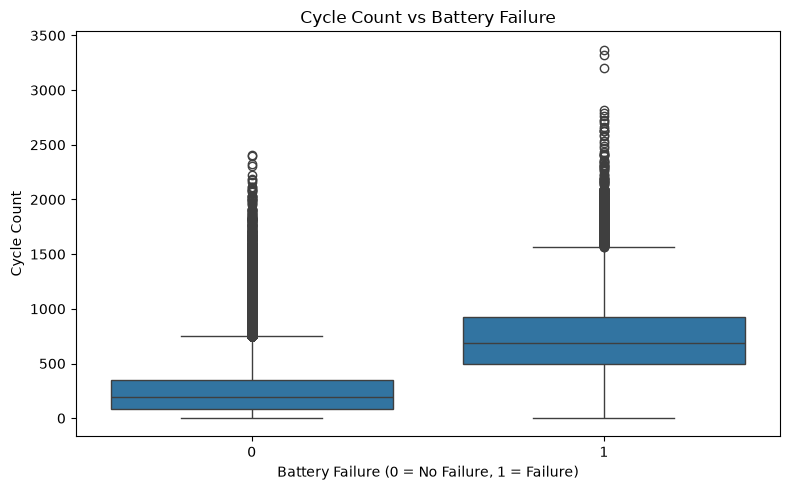

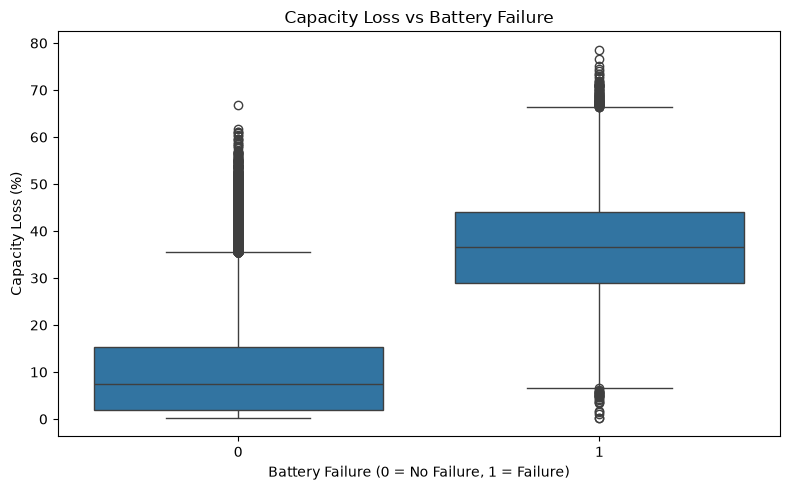

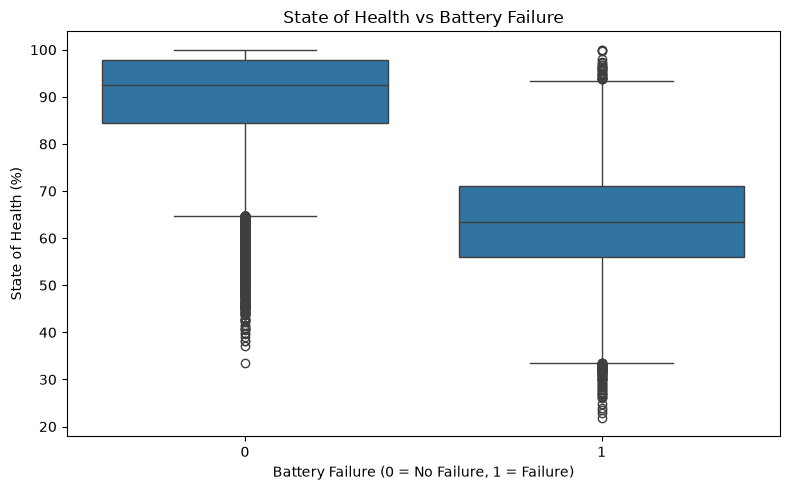

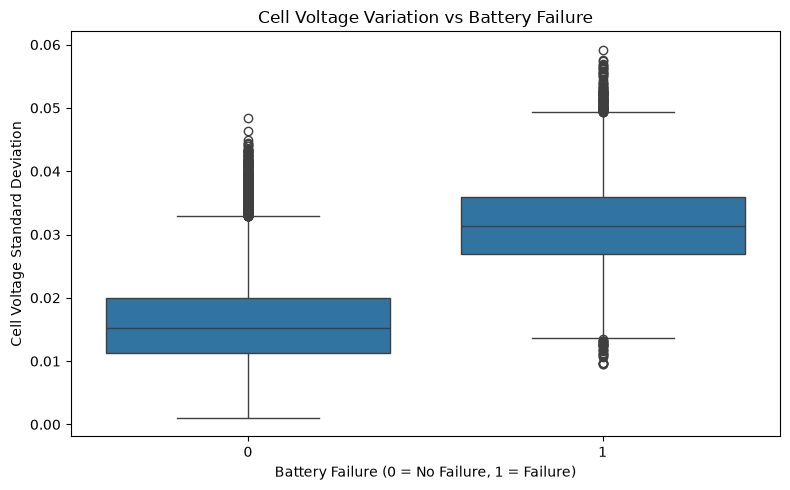

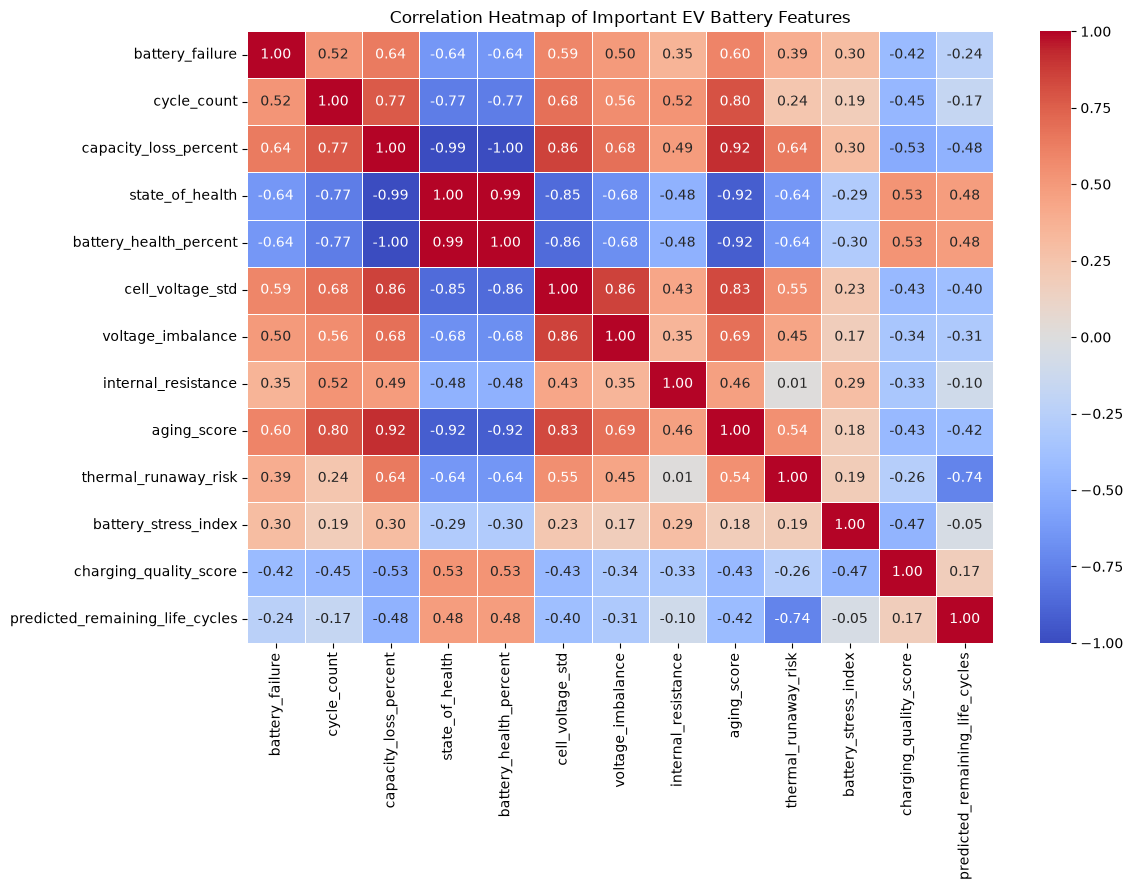

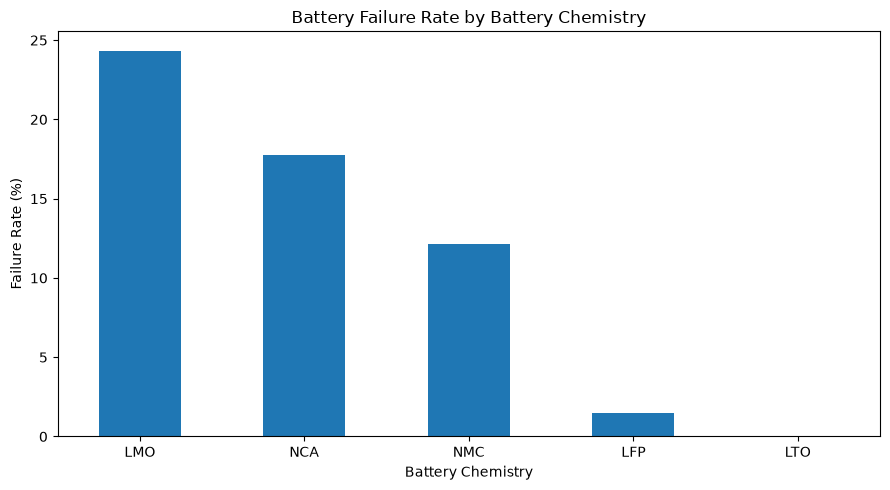

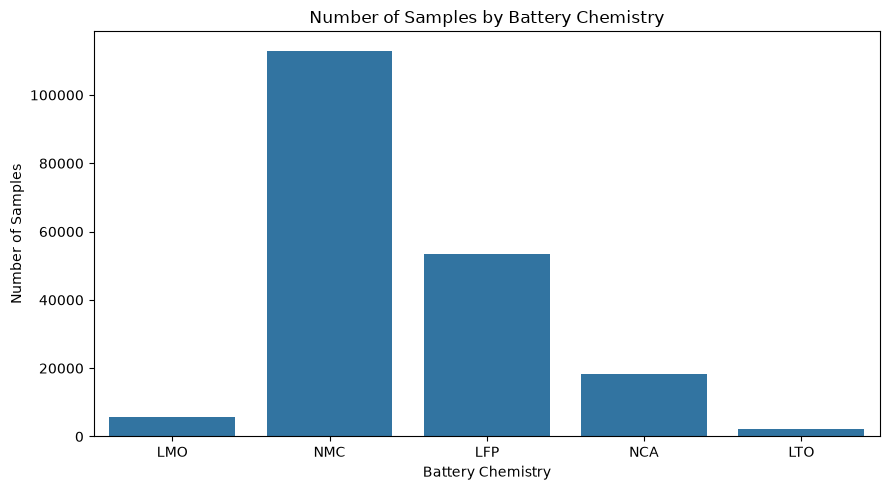

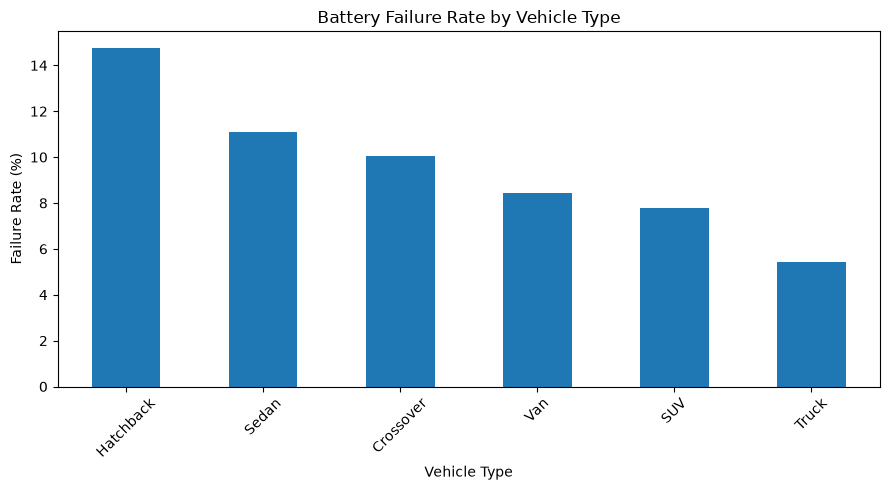

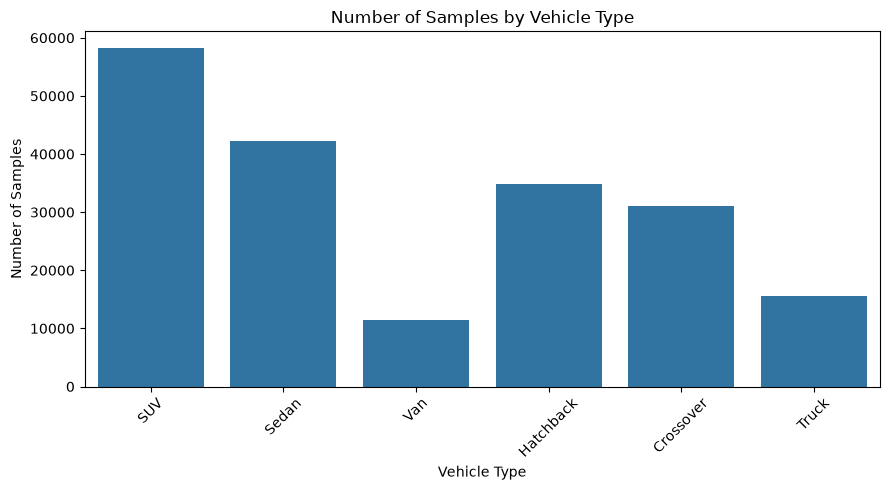

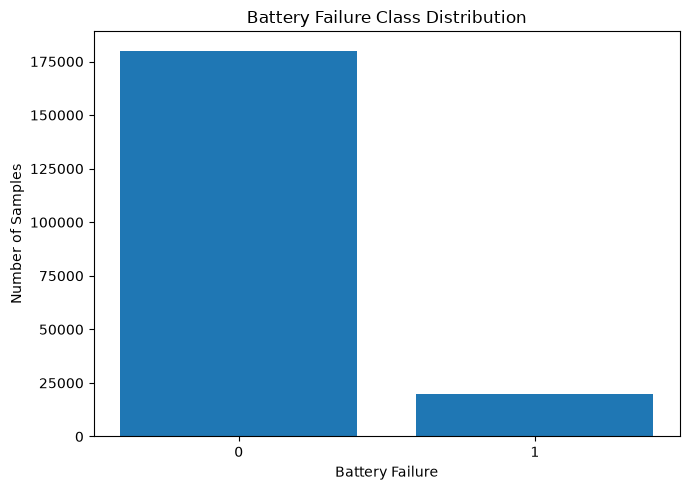

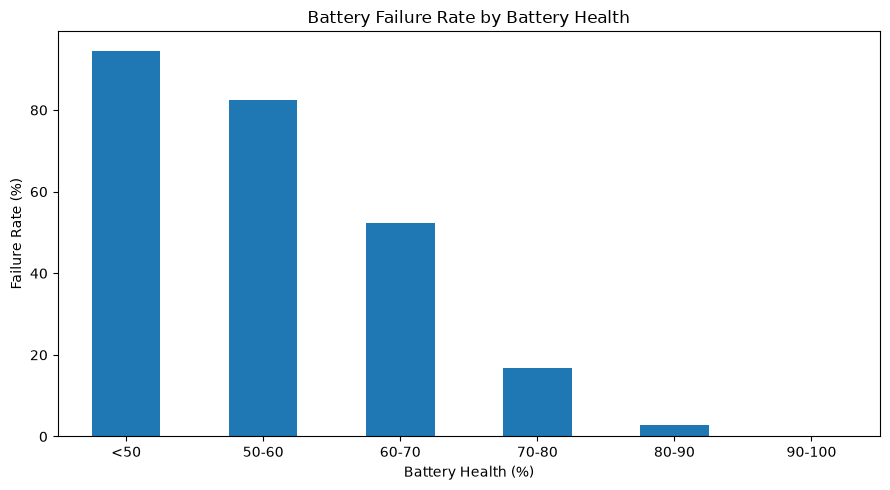

In [9]:
# 8. Visualizations
# --------------------------------------------------

def box_plot(col, title, y_label):
    if col in df.columns:
        plt.figure(figsize=(8, 5))
        sns.boxplot(data=df, x=target, y=col)
        plt.title(title)
        plt.xlabel("Battery Failure (0 = No Failure, 1 = Failure)")
        plt.ylabel(y_label)
        plt.tight_layout()
        plt.show()
    else:
        print(f"Skipping plot: '{col}' not found.")

box_plot("cycle_count", "Cycle Count vs Battery Failure", "Cycle Count")
box_plot("capacity_loss_percent", "Capacity Loss vs Battery Failure", "Capacity Loss (%)")
box_plot("state_of_health", "State of Health vs Battery Failure", "State of Health (%)")
box_plot("cell_voltage_std", "Cell Voltage Variation vs Battery Failure",
         "Cell Voltage Standard Deviation")

# Correlation heatmap
corr_cols = [
    target,
    "cycle_count",
    "capacity_loss_percent",
    "state_of_health",
    "battery_health_percent",
    "cell_voltage_std",
    "voltage_imbalance",
    "internal_resistance",
    "aging_score",
    "thermal_runaway_risk",
    "battery_stress_index",
    "charging_quality_score",
    "predicted_remaining_life_cycles"
]
corr_cols = [c for c in corr_cols if c in df.columns]

if len(corr_cols) > 1:
    corr = df[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        linewidths=0.5
    )
    plt.title("Correlation Heatmap of Important EV Battery Features")
    plt.tight_layout()
    plt.show()

# Failure rate by battery chemistry
if "battery_chemistry" in df.columns:
    chem_rate = (
        df.groupby("battery_chemistry")[target]
          .mean()
          .sort_values(ascending=False) * 100
    )

    plt.figure(figsize=(9, 5))
    chem_rate.plot(kind="bar")
    plt.title("Battery Failure Rate by Battery Chemistry")
    plt.xlabel("Battery Chemistry")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 5))
    sns.countplot(data=df, x="battery_chemistry")
    plt.title("Number of Samples by Battery Chemistry")
    plt.xlabel("Battery Chemistry")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

# Failure rate and sample count by vehicle type
if "vehicle_type" in df.columns:
    veh_rate = (
        df.groupby("vehicle_type")[target]
          .mean()
          .sort_values(ascending=False) * 100
    )

    plt.figure(figsize=(9, 5))
    veh_rate.plot(kind="bar")
    plt.title("Battery Failure Rate by Vehicle Type")
    plt.xlabel("Vehicle Type")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 5))
    sns.countplot(data=df, x="vehicle_type")
    plt.title("Number of Samples by Vehicle Type")
    plt.xlabel("Vehicle Type")
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Target class distribution
plt.figure(figsize=(7, 5))
fail_counts = df[target].value_counts().sort_index()
plt.bar(fail_counts.index.astype(str), fail_counts.values)
plt.title("Battery Failure Class Distribution")
plt.xlabel("Battery Failure")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# Failure rate by battery health groups
if "battery_health_percent" in df.columns:
    health_bins = [0, 50, 60, 70, 80, 90, 100]
    health_labels = ["<50", "50-60", "60-70", "70-80", "80-90", "90-100"]

    df["health_group"] = pd.cut(
        df["battery_health_percent"],
        bins=health_bins,
        labels=health_labels,
        include_lowest=True
    )

    health_rate = (
        df.groupby("health_group", observed=False)[target].mean() * 100
    )

    plt.figure(figsize=(9, 5))
    health_rate.plot(kind="bar")
    plt.title("Battery Failure Rate by Battery Health")
    plt.xlabel("Battery Health (%)")
    plt.ylabel("Failure Rate (%)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### Notes on the preprocessing section

- Numerical missing values are replaced with the training-set median, then standardized.
- Categorical missing values are replaced with `Unknown`; one-hot encoding ignores categories not seen during fitting.
- The preprocessing pipeline is fitted only on the training partition to reduce data leakage.
- The initial preprocessing output is useful for inspecting the transformation. The modeling section below
  creates its own train/test split and preprocessing pipeline so that the model comparison workflow is
  self-contained. Run all cells in order because the modeling section uses the loaded `df`.

## Part 2 — Classification model training and evaluation

This section independently prepares the modeling data, compares three classifiers, selects a threshold on validation data, and evaluates the final model on the held-out test set.

### 10. Import modeling and evaluation libraries

Load the estimators and classification metrics required for model comparison and final evaluation.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    precision_recall_curve
)

### 11. Separate predictors and target

Create `X` from all columns except the target and the two identifier columns. Create `y` from the battery-failure label.

In [11]:
# 1. Separate features and target
X = df.drop(columns=['battery_failure', 'vehicle_id', 'battery_serial'])
y = df['battery_failure']

### 12. Split into training and test sets

Reserve 20% of the records for final testing. Stratification keeps the class distribution comparable across partitions.

In [12]:
# 2. Train-test split
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

### 13. Detect numerical and categorical columns

Identify feature types from the training partition so that the appropriate transformations can be applied.

In [13]:
# 3. Identify columns
num_cols = X_tr.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_tr.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))

Numerical features: 59
Categorical features: 9


### 14. Define numerical preprocessing

Impute missing numerical values with the median and standardize the resulting features.

In [14]:
# 4. Numerical preprocessing
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

### 15. Define categorical preprocessing

Fill missing categorical values with `Unknown` and one-hot encode categories. Unseen categories at transform time are ignored.

In [15]:
# 5. Categorical preprocessing
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

### 16. Combine preprocessing and transform data

Use a `ColumnTransformer` to apply the correct pipeline to each feature group. Fit it only on training data and transform the test data without refitting.

In [16]:
# 6. Combine preprocessing
prep = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

# Fit only on training data
X_tr_p = prep.fit_transform(X_tr)
X_te_p = prep.transform(X_te)

print("\nProcessed training:", X_tr_p.shape)
print("Processed testing:", X_te_p.shape)


Processed training: (160000, 179)
Processed testing: (40000, 179)


### 17. Create a validation split

Split the processed training data again. The validation partition is used for model comparison and decision-threshold selection; the test set remains untouched.

In [17]:
# 7. Validation split
X_a, X_v, y_a, y_v = train_test_split(
    X_tr_p, y_tr,
    test_size=0.20,
    random_state=42,
    stratify=y_tr
)

print("\nModel training:", X_a.shape)
print("Validation:", X_v.shape)


Model training: (128000, 179)
Validation: (32000, 179)


### 18. Define candidate classifiers

Set up Logistic Regression, Random Forest, and Extra Trees with class-weight handling to account for possible class imbalance.

In [18]:
# 8. Define models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    )
}

### 19. Train and evaluate candidate models

Fit each model on the model-training subset. Evaluate validation probabilities at the default 0.5 threshold, then find the threshold that maximizes validation F1.

In [19]:
# 9. Train and evaluate models
results = []
trained_models = {}
thresholds_dict = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_a, y_a)

    y_prob = model.predict_proba(X_v)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # Metrics
    acc = accuracy_score(y_v, y_pred)
    pre = precision_score(y_v, y_pred, zero_division=0)
    rec = recall_score(y_v, y_pred, zero_division=0)
    f1 = f1_score(y_v, y_pred, zero_division=0)
    roc = roc_auc_score(y_v, y_prob)
    pr = average_precision_score(y_v, y_prob)

    # Find best F1 threshold
    p, r, t = precision_recall_curve(y_v, y_prob)

    f1_values = (
        2 * p[:-1] * r[:-1] /
        (p[:-1] + r[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_values)
    best_th = t[best_idx]

    thresholds_dict[name] = best_th
    trained_models[name] = model

    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': pre,
        'Recall': rec,
        'F1 Score': f1,
        'ROC-AUC': roc,
        'PR-AUC': pr,
        'Best Threshold': best_th,
        'Best Validation F1': f1_values[best_idx]
    })

    print(name, "completed.")


Training Logistic Regression...
Logistic Regression completed.

Training Random Forest...
Random Forest completed.

Training Extra Trees...
Extra Trees completed.


### 20. Compare model results

Collect the validation metrics and selected threshold into a single comparison table.

In [20]:
# 10. Model comparison
res = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(res.round(4))


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Best Threshold,Best Validation F1
0,Logistic Regression,0.9418,0.6383,0.9602,0.7668,0.9898,0.9238,0.8656,0.8369
1,Random Forest,0.9578,0.8003,0.7684,0.7841,0.9834,0.8772,0.4909,0.7867
2,Extra Trees,0.9456,0.6764,0.8698,0.7610,0.9812,0.8667,0.6171,0.7776


### 21. Plot model performance

Create a separate bar chart for each validation metric to make model differences easier to compare.

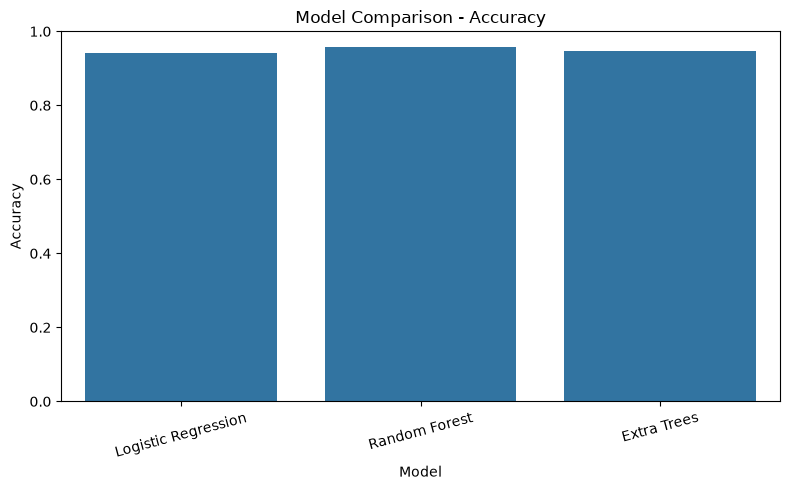

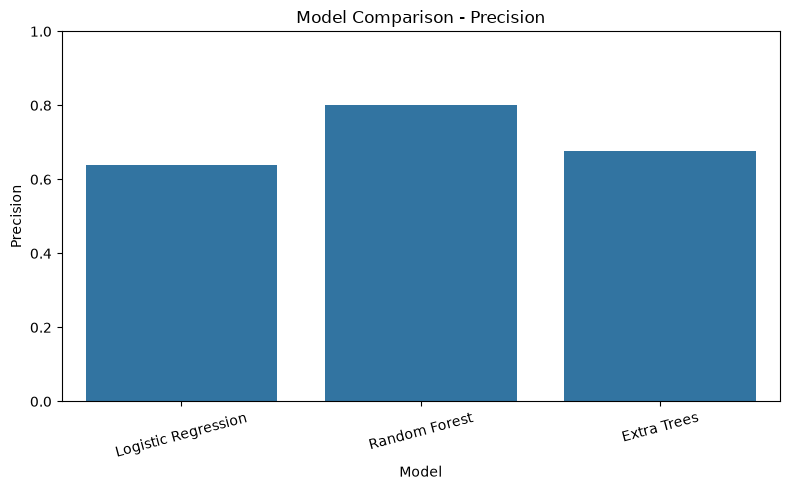

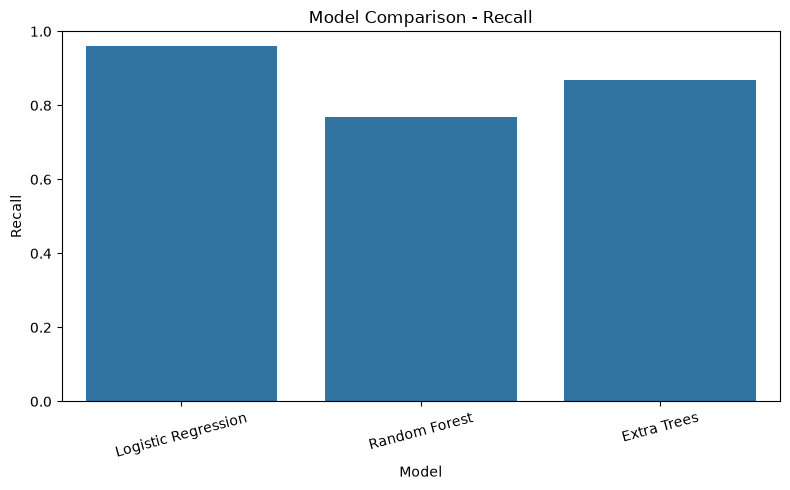

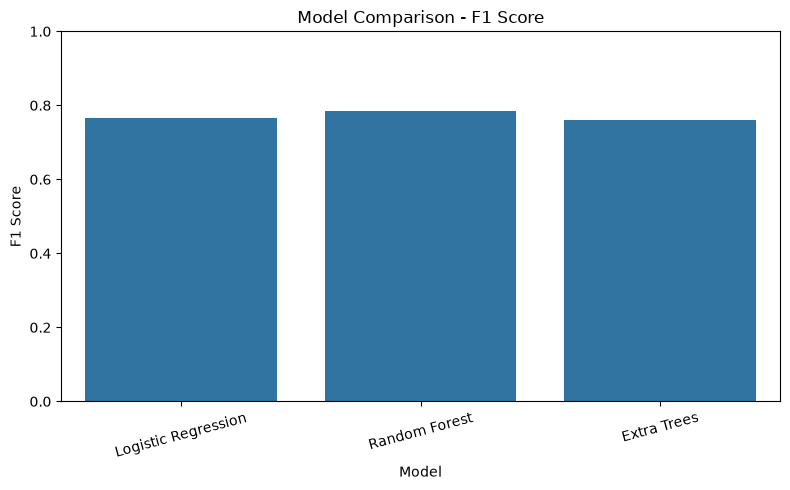

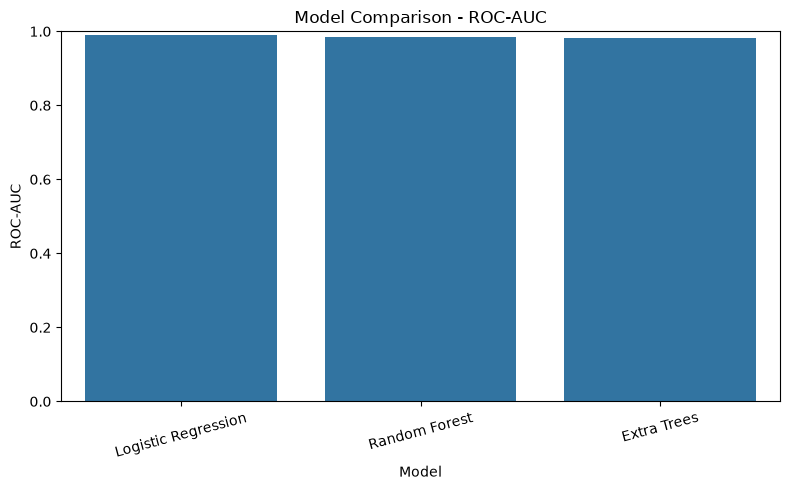

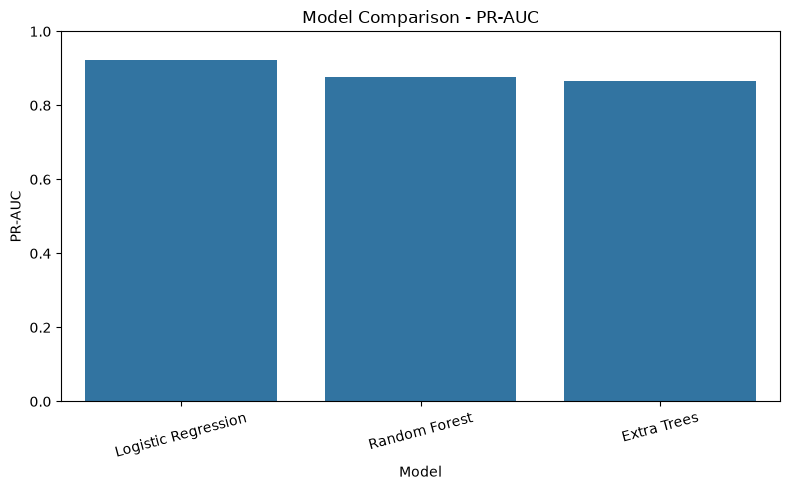

In [21]:
# 11. Visualize model performance
metrics = [
    'Accuracy', 'Precision', 'Recall',
    'F1 Score', 'ROC-AUC', 'PR-AUC'
]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=res,
        x='Model',
        y=metric
    )

    plt.title(f'Model Comparison - {metric}')
    plt.ylim(0, 1)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

### 22. Select the best model and threshold

Choose the candidate with the highest validation F1 and retrieve its corresponding validation-selected threshold.

In [22]:
# 12. Select best model using validation F1
best_name = res.loc[
    res['Best Validation F1'].idxmax(),
    'Model'
]

best_th = thresholds_dict[best_name]
best_model = trained_models[best_name]

print("\nBest Model:", best_name)
print("Best Threshold:", round(best_th, 4))


Best Model: Logistic Regression
Best Threshold: 0.8656


### 23. Retrain the selected model

Refit the selected estimator using the complete training partition, including the records used for validation.

In [23]:
# 13. Retrain best model on complete training data
best_model.fit(X_tr_p, y_tr)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

### 24. Predict on the test set

Generate failure probabilities for the held-out test records and convert them to class predictions using the selected threshold.

In [24]:
# 14. Final test predictions
y_prob = best_model.predict_proba(X_te_p)[:, 1]
y_pred = (y_prob >= best_th).astype(int)

### 25. Evaluate final test performance

Report the classification report, accuracy, precision, recall, F1, ROC-AUC, and average precision on the test set.

In [25]:
# 15. Final evaluation
print("\nFINAL TEST CLASSIFICATION REPORT\n")

print(classification_report(
    y_te,
    y_pred,
    target_names=['No Failure', 'Failure'],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_te, y_pred))
print("Precision:", precision_score(y_te, y_pred, zero_division=0))
print("Recall:", recall_score(y_te, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_te, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_te, y_prob))
print("PR-AUC:", average_precision_score(y_te, y_prob))


FINAL TEST CLASSIFICATION REPORT

              precision    recall  f1-score   support

  No Failure       0.98      0.98      0.98     36016
     Failure       0.82      0.85      0.83      3984

    accuracy                           0.97     40000
   macro avg       0.90      0.91      0.91     40000
weighted avg       0.97      0.97      0.97     40000

Accuracy: 0.966125
Precision: 0.8199075200778778
Recall: 0.8456325301204819
F1 Score: 0.8325713579636723
ROC-AUC: 0.9893484491609262
PR-AUC: 0.922589474183096


### 26. Inspect the confusion matrix

Visualize true versus predicted classes to understand the types and counts of classification errors.

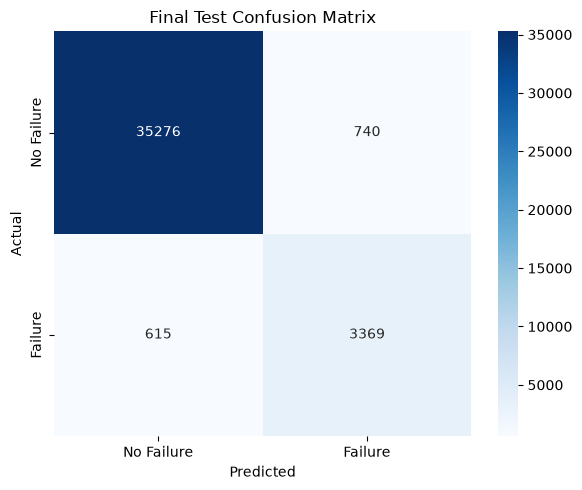

In [26]:
# 16. Confusion matrix
cm = confusion_matrix(y_te, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Final Test Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## Interpretation and good-practice reminders

- **Recall for the failure class** measures how many actual battery failures are detected. In a safety-related use case, missed failures may be especially costly.
- **Precision** measures how many predicted failures are actual failures. Lower precision can lead to more false alarms.
- **F1** balances precision and recall; it is the metric currently used to select the decision threshold.
- **ROC-AUC** and **average precision (PR-AUC)** evaluate ranking quality from predicted probabilities rather than one fixed threshold.
- The final test metrics are an estimate of performance on unseen data. Do not repeatedly adjust features, models, or thresholds based on test results.
- The feature names listed as potentially engineered/leakage-prone require domain knowledge and a check of when each value becomes available. A feature derived after a failure event must not be used for a real-time pre-failure prediction task.
- This notebook reports model performance; it does not establish that the model is safe or suitable for deployment. Further validation, calibration, temporal testing, and domain review may be required.